# End-to-End Classification Workflow

This notebook follows a logical ML workflow:
1. Problem Statement
2. Data Understanding & Distribution
3. Model Training
4. Hyperparameter Tuning & Cross-Validation
5. Evaluation Metrics
6. ROC & Precision-Recall Curves
7. Threshold Adjustment & Business Decision


# Problem Statement

We are building a classification model to predict residential out-migration (Y=1) based on various features. The goal is to inform targeted interventions under the Programme for Government.

---

# 🎯 Why Precision Is the Primary Metric (Cost-Based Framing)

## Policy Context

We are predicting **residential out-migration (Y=1)** to inform targeted interventions under the Programme for Government.

Public funds are limited. Every intervention must be defensible.

---

## The Cost Structure

### False Positive (FP)

We intervene, but the resident would have stayed anyway.

**Cost:**

* Deadweight loss (wasted subsidy)
* Reduced funds for genuine cases
* Audit and accountability risk

This is an **immediate, measurable fiscal cost**.

---

### False Negative (FN)

We fail to intervene, and the resident leaves.

**Cost:**

* Long-term economic and demographic impact
* Harder to measure directly in the short term

This is a **strategic, longer-term cost**.

---

## Why Precision Is Prioritised

Precision answers:

> “When we intervene, how often are we correct?”

[
Precision = \frac{TP}{TP + FP}
]

High precision ensures:

* Interventions are tightly targeted
* Public money is not wasted
* Decisions withstand scrutiny

In a resource-constrained public sector environment, avoiding waste is critical.

---

## Policy Trade-Off

We accept:

* Some at-risk residents may not be identified (lower recall)

In exchange for:

* High confidence that funded interventions are justified

This is a deliberate choice to prioritise **resource efficiency and accountability**.



Importing necessary libraries and loading the dataset

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score,
    precision_recall_curve, auc
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)


## 2. Data Generation & Distribution


generate synthetic data for the classification task

In [139]:
X, y = make_classification(
    n_samples=1000,
    n_features=9,
    n_informative=2,
    n_redundant=0,
    weights=[0.9, 0.1],
    random_state=42
)

X = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(9)])
y = pd.Series(y, name='Out-Migration Status')

print(y.value_counts(normalize=True))


Out-Migration Status
0    0.898
1    0.102
Name: proportion, dtype: float64


It appears that the ddataset is imbalanced - accuracy is not a good metric to evaluate the model performance. We will use precision as our primary metric to evaluate the model performance.

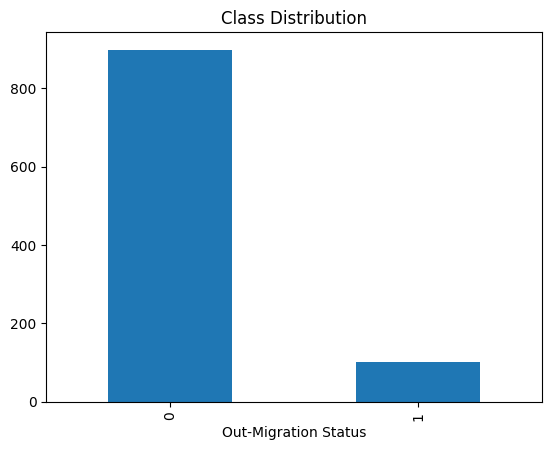

In [140]:
y.value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.show()


## 3. Train/Test Split


In [141]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

## 4. Model Training


Let fit the Logistic Regression, Decision Tree, and Random Forest models

In [142]:
# creating then fitting the logistic regression momdel
model_lr = LogisticRegression()
model_lr.fit(X_train, y_train)

# creating then fitting the deicions tree and random forest models
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)

# creating then fitting the random forest model
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In the next section we jump straight to cross validation as the single train/test split is not enough to evaluate the models. (remeber, our  model might get lucky with the train/test split so we need to do more than one split to get a better estimate of the model performance)

## 5. Cross-Validation 


### We choose the main metric based on the business consequences of false positives and false negatives

- we have the choice between precision,recall, f1-score, accuracy

In [147]:
cv_scores_lr = cross_validate(model_lr, X_train, y_train, cv=10, scoring="precision")
cv_results_lr = pd.DataFrame(cv_scores_lr)
print(cv_results_lr["test_score"].describe())

count    10.000000
mean      0.743333
std       0.136581
min       0.500000
25%       0.687500
50%       0.750000
75%       0.812500
max       1.000000
Name: test_score, dtype: float64


In [148]:
cv_scores_dt = cross_validate(model_dt, X_train, y_train, cv=10, scoring="precision")
cv_results_dt = pd.DataFrame(cv_scores_dt)
print(cv_results_dt["test_score"].describe())

count    10.000000
mean      0.724643
std       0.096531
min       0.555556
25%       0.666667
50%       0.732143
75%       0.794444
max       0.857143
Name: test_score, dtype: float64


In [149]:
cv_scores_rf = cross_validate(model_rf, X_train, y_train, cv=10, scoring="precision")
cv_results_rf = pd.DataFrame(cv_scores_rf)
print(cv_results_rf["test_score"].describe())

count    10.000000
mean      0.909524
std       0.103358
min       0.714286
25%       0.839286
50%       0.928571
75%       1.000000
max       1.000000
Name: test_score, dtype: float64


Rather than try to manually cross reference the precision scores across the different models, we can use boxplots to visualise the distribution of precision scores across the different models.

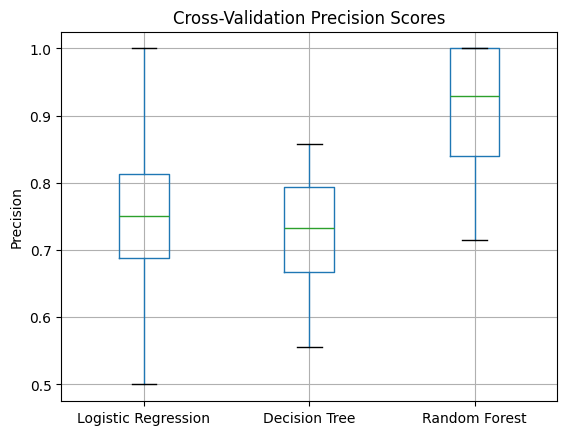

In [150]:
# plot as boxplot
cv_results = pd.DataFrame({
    'Logistic Regression': cv_results_lr['test_score'],
    'Decision Tree': cv_results_dt['test_score'],
    'Random Forest': cv_results_rf['test_score']
})
cv_results.boxplot()
plt.title('Cross-Validation Precision Scores')
plt.ylabel('Precision')
plt.show()

Based on intital analysis, the decision decision tree appears to have a much harder time being consistent in its precision scores. 

# 5b. Hyperparameter Tuning

In [158]:
param_grid = {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2'], 'solver': ['liblinear']}

grid_lr = GridSearchCV(LogisticRegression(), param_grid, cv=10, scoring='precision')
grid_lr.fit(X_train, y_train)

best_model_lr = grid_lr.best_estimator_
print('Best parameters:', grid_lr.best_params_)
print('Best CV Precision (Logistic Regression):', grid_lr.best_score_)


Best parameters: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Precision (Logistic Regression): 0.7740476190476191


In [159]:

param_grid = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=10,
    scoring='f1'
)

grid_dt.fit(X_train, y_train)

best_model_dt = grid_dt.best_estimator_
print('Best parameters:', grid_dt.best_params_)
print('Best CV F1 (Decision Tree):', grid_dt.best_score_)   

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1 (Decision Tree): 0.7619702519702519


In [160]:
param_grid = {
    'n_estimators': [100,150,200],          # 100 = default
    'max_depth': [None, 10, 20],         # None = default
    'min_samples_split': [2, 5],         # 2 = default
    'min_samples_leaf': [1, 2]           # 1 = default
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=10,
    scoring='precision'
)

grid_rf.fit(X_train, y_train)

best_model_rf = grid_rf.best_estimator_
print('Best parameters:', grid_rf.best_params_)
print('Best CV Precision (Random Forest):', grid_rf.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Precision (Random Forest): 0.911904761904762


In [137]:
# Decision Tree
best_index_dt = grid_dt.best_index_

dt_scores = [
    grid_dt.cv_results_['split0_test_score'][best_index_dt],
    grid_dt.cv_results_['split1_test_score'][best_index_dt],
    grid_dt.cv_results_['split2_test_score'][best_index_dt],
    grid_dt.cv_results_['split3_test_score'][best_index_dt],
    grid_dt.cv_results_['split4_test_score'][best_index_dt],
]


# Random Forest
best_index_rf = grid_rf.best_index_

rf_scores = [
    grid_rf.cv_results_['split0_test_score'][best_index_rf],
    grid_rf.cv_results_['split1_test_score'][best_index_rf],
    grid_rf.cv_results_['split2_test_score'][best_index_rf],
    grid_rf.cv_results_['split3_test_score'][best_index_rf],
    grid_rf.cv_results_['split4_test_score'][best_index_rf],
]


# Logistic Regression
best_index_lr = grid_lr.best_index_

lr_scores = [
    grid_lr.cv_results_['split0_test_score'][best_index_lr],
    grid_lr.cv_results_['split1_test_score'][best_index_lr],
    grid_lr.cv_results_['split2_test_score'][best_index_lr],
    grid_lr.cv_results_['split3_test_score'][best_index_lr],
    grid_lr.cv_results_['split4_test_score'][best_index_lr],
]

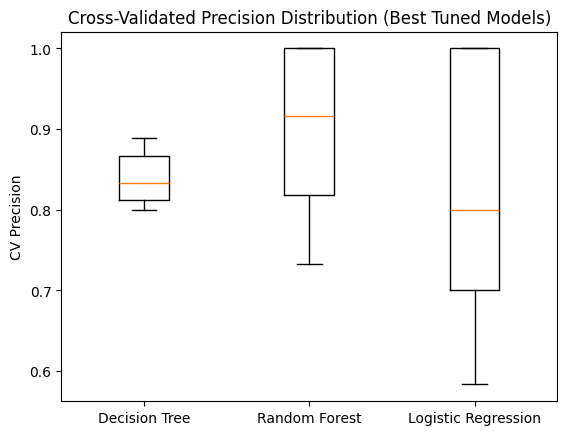

In [162]:
import matplotlib.pyplot as plt

plt.boxplot([dt_scores, rf_scores, lr_scores])
plt.xticks([1, 2, 3], ['Decision Tree', 'Random Forest', 'Logistic Regression'])
plt.ylabel('CV Precision')
plt.title('Cross-Validated Precision Distribution (Best Tuned Models)')
plt.show()

In [122]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint

param_dist = {
    'max_depth': np.linspace(1, 51, 51, dtype=int),
    'min_samples_split': np.linspace(2, 51, 50, dtype=int),
    'min_samples_leaf': np.linspace(1, 21, 21, dtype=int),
    'max_features': [None, 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy', 'log_loss']
}

random_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=200,        # try only 100 random combinations
    cv=5,
    scoring='precision',
    random_state=42
)

random_search.fit(X_train, y_train)

best_model_dt = random_search.best_estimator_

print("Best parameters:", random_search.best_params_)
print("Best CV Precision:", random_search.best_score_)

/opt/anaconda3/envs/python-starter/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/python-starter/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/python-starter/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

Best parameters: {'min_samples_split': np.int64(31), 'min_samples_leaf': np.int64(14), 'max_features': 'sqrt', 'max_depth': np.int64(4), 'criterion': 'entropy'}
Best CV Precision: 1.0


## 6. Evaluation Metrics


now that we have our best model lets see “How well will the chosen model perform on new data?”

In [123]:
best_model = best_model_lr 

In [124]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))


Accuracy: 0.9633333333333334
Precision: 1.0
Recall: 0.65625
F1: 0.7924528301886793


In [106]:
# ------------------------------------------------------------
# Bootstrap 95% CI for TEST precision (model fixed, resample test rows)
# ------------------------------------------------------------
rng = np.random.default_rng(42)

n_boot = 5000
n = len(y_test)

boot_precisions = np.empty(n_boot)

# convert to numpy arrays to allow fancy indexing reliably
y_true = np.asarray(y_test)
y_hat = np.asarray(y_pred)

for b in range(n_boot):
    idx = rng.integers(0, n, size=n)  # sample indices with replacement
    boot_precisions[b] = precision_score(y_true[idx], y_hat[idx], zero_division=0)

ci_low, ci_high = np.percentile(boot_precisions, [2.5, 97.5])

print(f"Precision (bootstrap 95% CI): [{ci_low:.4f}, {ci_high:.4f}]")

Precision (bootstrap 95% CI): [0.9277, 1.0000]


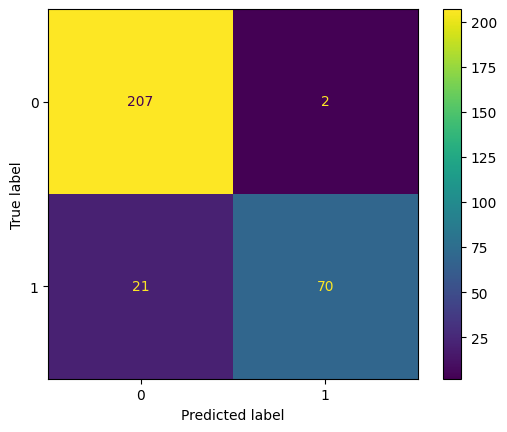

In [107]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

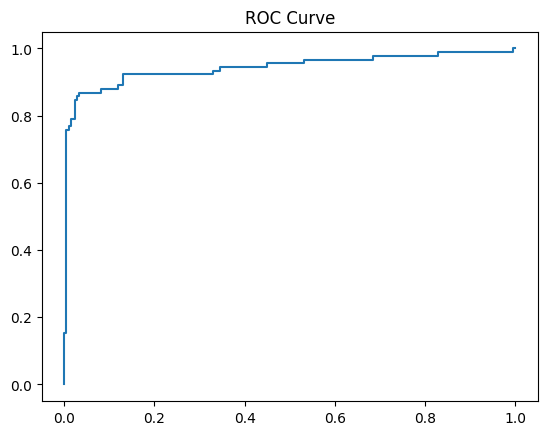

In [101]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr)
plt.title('ROC Curve')
plt.show()

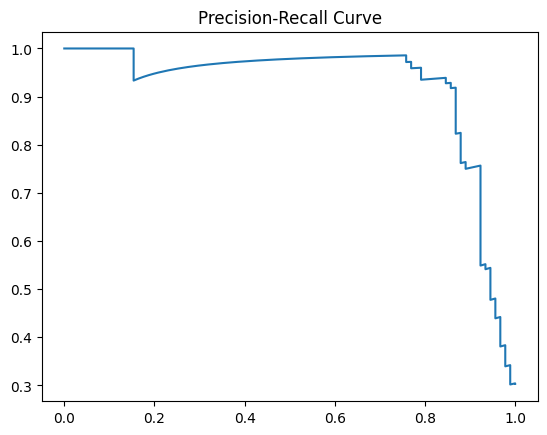

In [102]:
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_proba)
plt.plot(recall_vals, precision_vals)
plt.title('Precision-Recall Curve')
plt.show()